## Performs the memory experiment with toy noise on repetion circuits with transversal and standard syndrome extraction comparing the respective performances

In [1]:
import sys
from pathlib import Path

import numpy as np
import stim
import pymatching
from deltakit.explorer.qpu import QPU, ToyNoise, ExhaustiveGateSet
from matplotlib import pyplot as plt

# make src/ importable (the notebook runs from notebooks/)
sys.path.insert(0, str(Path.cwd().parent / "src"))
import repetetion as Repetetion
from util import to_deltakit

# 01. Creating the circuit

We use the helper files in src to create Z-basis memory experiments (bit-flip code) with `3*d` rounds of syndrome extraction, for three schemes:

- **transversal**: transversal extraction with a serial CNOT-ladder GHZ preparation and one ancilla block (`ghz='ladder', blocks=1`).
- **transversal (improved)**: log-depth bisection-tree GHZ preparation, with GHZ states for the next rounds prepared on 4 ancilla blocks in rotation (`ghz='bisect', blocks=4`). See the docstrings in `src/repetetion.py`.
- **standard**: one ancilla per stabilizer.

Noise is added with deltakit's `ToyNoise(p)`: two-qubit depolarising noise `p` after every CNOT, single-qubit depolarising `p/10` after one-qubit gates, resets, measurements and on idling qubits, and measurement flips with probability `p`.

Notes on the deltakit conversion (`src/util.py: to_deltakit`):
- deltakit parses circuits with its own `deltakit_stim` fork. Its `from_stim_circuit` also puts every stim instruction in its own layer, which would add spurious idle noise when one TICK contains different gates (as in the pipelined circuit). `to_deltakit` builds one layer per TICK instead.
- `ExhaustiveGateSet()` is passed because the default native gate set has no `RX`.

In [2]:
distance = [3, 5, 7, 9]
error = [0.001, 0.005, 0.01, 0.02, 0.05]

MAX_SHOTS = 1_000_000   # upper limit on shots per (circuit, d, p)
MAX_ERRORS = 1_000      # stop early once this many logical errors are seen
BATCH = 50_000


def add_noise(circuit: stim.Circuit, p: float) -> stim.Circuit:
    """Add ToyNoise(p) to a noiseless stim circuit using deltakit."""
    dk_circuit = to_deltakit(circuit)
    # keep the TICK layout of the circuit as written (no re-scheduling)
    qpu = QPU(dk_circuit.qubits, native_gates_and_times=ExhaustiveGateSet(),
              noise_model=ToyNoise(p=p), maximise_parallelism=False)
    noisy = qpu.add_noise_to_circuit(dk_circuit)
    return stim.Circuit(str(noisy.as_stim_circuit()))


def logical_error_rate(circuit: stim.Circuit):
    """Sample the noisy circuit, decode with pymatching and return (errors, shots)."""
    dem = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    sampler = circuit.compile_detector_sampler()
    errors, shots = 0, 0
    while shots < MAX_SHOTS and errors < MAX_ERRORS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        predictions = matcher.decode_batch(dets)
        errors += int(np.sum(np.any(predictions != obs, axis=1)))
        shots += BATCH
    return errors, shots


schemes = ["transversal", "transversal (improved)", "standard"]
results = {name: {} for name in schemes}   # results[scheme][(d, p)] = (errors, shots)

for d in distance:
    circuits = {
        "transversal": Repetetion.circuit_transversal(distance=d, rounds=3*d, ghz="ladder", blocks=1),
        "transversal (improved)": Repetetion.circuit_transversal(distance=d, rounds=3*d, ghz="bisect", blocks=4),
        "standard": Repetetion.circuit_standard(distance=d, rounds=3*d),
    }

    for p in error:
        for name, circuit in circuits.items():
            # add noise using deltakit
            noisy_circuit = add_noise(circuit, p)

            # create the dem and decode with pymatching, compute the logical error rate
            errors, shots = logical_error_rate(noisy_circuit)
            results[name][(d, p)] = (errors, shots)
            print(f"{name:22s} d={d} p={p:<6} p_L={errors/shots:.2e}  ({errors}/{shots})")

transversal            d=3 p=0.001  p_L=1.74e-04  (174/1000000)
transversal (improved) d=3 p=0.001  p_L=1.06e-04  (106/1000000)
standard               d=3 p=0.001  p_L=9.30e-05  (93/1000000)
transversal            d=3 p=0.005  p_L=3.59e-03  (1078/300000)


transversal (improved) d=3 p=0.005  p_L=2.43e-03  (1093/450000)
standard               d=3 p=0.005  p_L=2.24e-03  (1006/450000)
transversal            d=3 p=0.01   p_L=1.35e-02  (1354/100000)
transversal (improved) d=3 p=0.01   p_L=9.55e-03  (1432/150000)
standard               d=3 p=0.01   p_L=8.87e-03  (1331/150000)
transversal            d=3 p=0.02   p_L=4.63e-02  (2313/50000)
transversal (improved) d=3 p=0.02   p_L=3.46e-02  (1731/50000)


standard               d=3 p=0.02   p_L=3.41e-02  (1704/50000)
transversal            d=3 p=0.05   p_L=2.01e-01  (10069/50000)
transversal (improved) d=3 p=0.05   p_L=1.62e-01  (8095/50000)
standard               d=3 p=0.05   p_L=1.55e-01  (7768/50000)


transversal            d=5 p=0.001  p_L=5.00e-06  (5/1000000)


transversal (improved) d=5 p=0.001  p_L=1.00e-06  (1/1000000)


standard               d=5 p=0.001  p_L=1.00e-06  (1/1000000)


... (35 outputs left out)

standard               d=9 p=0.02   p_L=9.64e-04  (964/1000000)


transversal            d=9 p=0.05   p_L=3.58e-01  (17907/50000)


transversal (improved) d=9 p=0.05   p_L=1.32e-01  (6621/50000)


standard               d=9 p=0.05   p_L=8.06e-02  (4032/50000)


# 02. Plot and compare the results

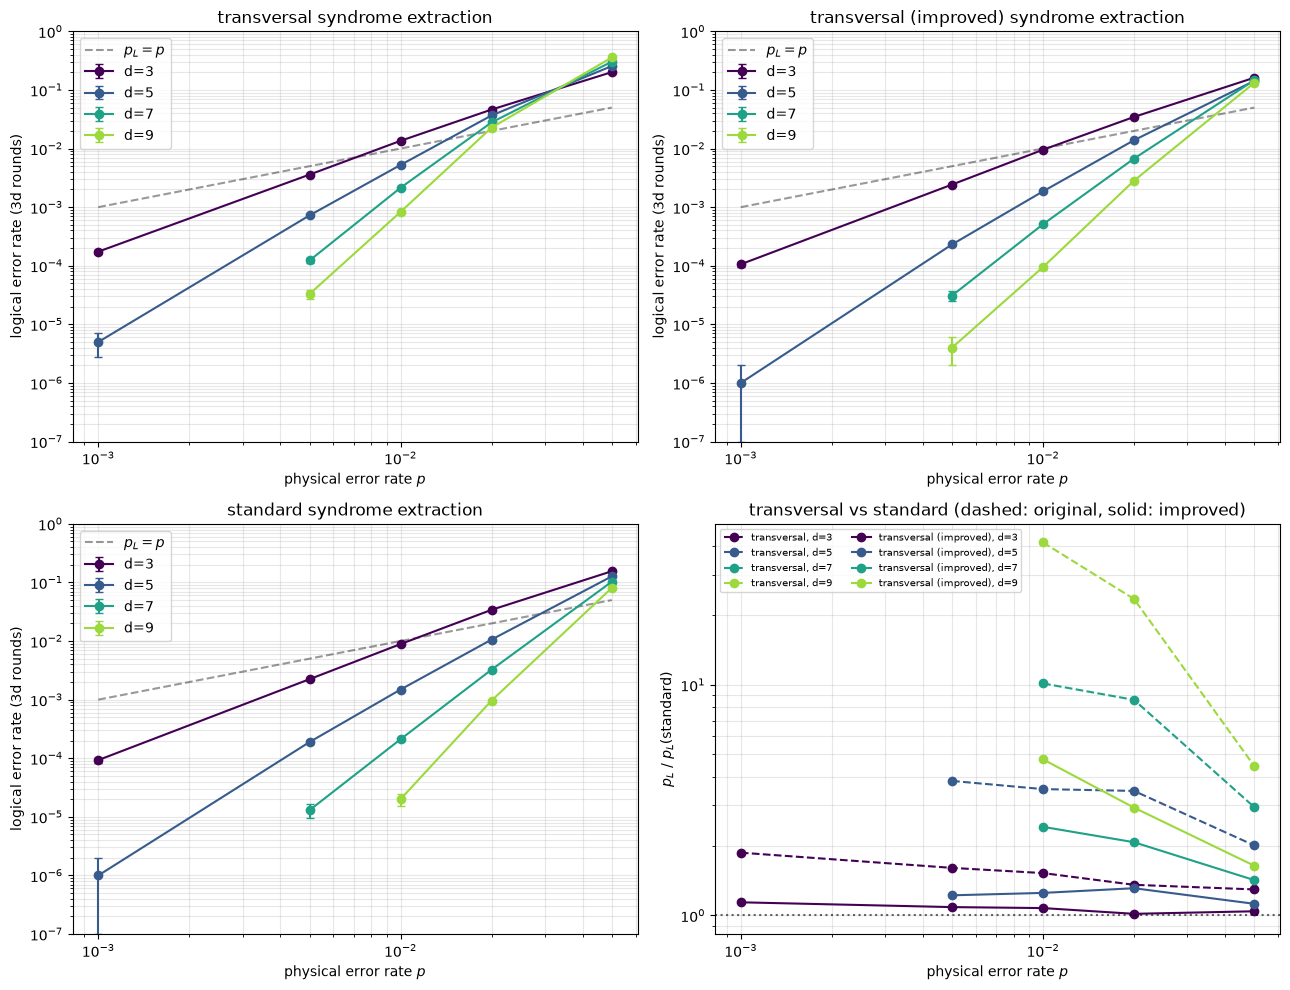

In [3]:
def rate_and_err(errors, shots):
    p_L = errors / shots
    return p_L, np.sqrt(p_L * (1 - p_L) / shots)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
colors = plt.cm.viridis(np.linspace(0, 0.85, len(distance)))

# logical error rate vs physical error rate, one panel per scheme
for ax, name in zip(axes.flat[:3], schemes):
    for d, c in zip(distance, colors):
        pL, err = np.array([rate_and_err(*results[name][(d, p)]) for p in error]).T
        mask = pL > 0   # zero observed errors cannot be shown on a log axis
        yerr = [np.minimum(err, 0.9 * pL)[mask], err[mask]]   # keep lower bars above zero on log axis
        ax.errorbar(np.array(error)[mask], pL[mask], yerr=yerr, marker="o", capsize=3, color=c, label=f"d={d}")
    ax.plot(error, error, "k--", alpha=0.4, label="$p_L = p$")
    ax.set(xscale="log", yscale="log", ylim=(1e-7, 1), xlabel="physical error rate $p$",
           ylabel="logical error rate (3d rounds)", title=f"{name} syndrome extraction")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

# direct comparison: ratio of each transversal scheme to standard
ax = axes.flat[3]
for name, ls in (("transversal", "--"), ("transversal (improved)", "-")):
    for d, c in zip(distance, colors):
        ratio = []
        for p in error:
            (te, ts), (se, ss) = results[name][(d, p)], results["standard"][(d, p)]
            # skip ratios dominated by shot noise (too few observed errors)
            ratio.append((te / ts) / (se / ss) if min(te, se) >= 20 else np.nan)
        ax.plot(error, ratio, ls, marker="o", color=c, label=f"{name}, d={d}")
ax.axhline(1, color="k", ls=":", alpha=0.6)
ax.set(xscale="log", yscale="log", xlabel="physical error rate $p$", ylabel="$p_L$ / $p_L$(standard)",
       title="transversal vs standard (dashed: original, solid: improved)")
ax.legend(fontsize=7, ncol=2)
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# 03. Comments

**Setup:** Z-basis memory, `3d` rounds, deltakit `ToyNoise(p)`, decoded with PyMatching. Points with zero observed logical errors (out of $10^6$ shots) are not drawn. In the ratio panel, ratios with fewer than 20 errors on either side are hidden. The numbers quoted below come from one run, and sampling makes them vary by a few percent between runs.

**Standard extraction** behaves as expected for a repetition code. At every $p$ up to 5%, larger distance gives a lower logical error rate, so the threshold under this noise model is above 5%. At $p=1\%$, $p_L \approx 9\times10^{-3},\ 1.4\times10^{-3},\ 1.8\times10^{-4},\ 2.4\times10^{-5}$ for $d=3,5,7,9$.

**Original transversal extraction** (`ghz='ladder', blocks=1`) is worse at every point, and the gap grows with distance: ~1.4× at $d=3$ and ~35× at $d=9$ for $p=1\%$. Its threshold sits between 2% and 5%: at $p=5\%$ larger codes are *worse*. The cause is the serial CNOT ladder that prepares the GHZ state. It takes $d-1$ time steps per round, and the data qubits pick up idle noise the whole time, so the per-round error grows with $d$. (Merging the root's reset and H into a single `RX`, now done for every variant, saves one tick per round and helps only slightly.)

**Improved transversal extraction** (`ghz='bisect', blocks=4`) makes two changes:
1. *Log-depth GHZ preparation by interval bisection.* Each qubit owns a contiguous range of the block and copies itself to the midpoint. Depth drops from $d-1$ to $\lceil\log_2 d\rceil$, and every subtree stays a contiguous range, so a fault during preparation still flips only a contiguous block of ancilla outcomes. This matters: a naive breadth-first fan-out has the same depth but spreads faults to scattered ancillas, and in a prototype it performed far *worse* than the ladder, getting worse with $d$.
2. *Pipelining across 4 ancilla blocks.* The GHZ states for later rounds are prepared while the current round runs, so a new round starts every $\lceil(\lceil\log_2 d\rceil+3)/4\rceil$ ticks rather than every $\lceil\log_2 d\rceil+3$. The data idles far less between rounds. The cost is qubits: $5d$ instead of $2d$.

Together, at $d=9$, $p=1\%$, they lower $p_L$ from $8.4\times10^{-4}$ to $9.6\times10^{-5}$ (~9×). Larger distance now helps at every tested $p$, so the threshold is back to ~5%. For $d\le5$ the improved scheme is within ~1.2× of standard extraction.

**Remaining gap to standard extraction** (~2–5× at $d=7,9$ for $p=1$–$2\%$): each ancilla outcome enters two neighbouring parities, so a single ancilla measurement error fires twice as many detectors as in standard extraction. The GHZ preparation also adds CNOT faults that standard extraction does not have.
In case of the repetetion code, adding transversal extraction adds new points for error occurence but does not improve the error correction as the simple repetetion code does not suffer from hook errors.